**Network Intrusion Detection System – MCA Final-Year PBL Project**

We will develop your Network Intrusion Detection System (NIDS) using the UNSW-NB15 dataset and implement all 11 steps mentioned in your project description.

I recommend building this project in Google Colab or Jupyter Notebook first. Google Colab is easier because you don't need to configure Python libraries manually.

**1. Project overview**

**Network Intrusion Detection System**

Objective: Detect whether network traffic is normal or malicious using machine learning.

Technology stack
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Joblib
- Streamlit (final user interface)
  
  Three machine learning algorithms
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

**2. Complete project workflow**

We will follow this exact sequence without skipping any of your required steps.
Step	Implementation	Expected output
1	Load dataset	Dataset information
2	EDA	Graphs and analysis
3	Preprocessing	Clean numerical data
4	Train-test split	80:20 split
5	Model training	Three classifiers
6	Model evaluation	Accuracy, precision, recall, F1
7	Cross-validation	5-fold scores
8	Hyperparameter tuning	Best parameters
9	Best model selection	Final evaluation
10	New predictions	Normal / Malicious
11	Save and deploy	Reusable prediction system

Important project decision: We will use binary classification as the main project:
- 0 = Normal Traffic
- 1 = Malicious Traffic
We will use the label column as our target. We will exclude attack_cat from the input features because it reveals the attack category and would cause target leakage in this binary classification task.

3. Dataset download and setup
We will use the official pre-divided training and testing files.

Create this project folder:
Network_Intrusion_Detection/
│
├── dataset/
│   ├── UNSW_NB15_training-set.csv
│   └── UNSW_NB15_testing-set.csv
│
├── models/
│
├── outputs/
│
├── notebooks/
│   └── Network_Intrusion_Detection.ipynb
│
├── app.py
├── predict.py
└── requirements.txt


For now, we will implement everything inside one notebook, cell by cell. Later, we will create app.py and predict.py.

**4. Complete Google Colab implementation**

Before starting
1. Open Google Colab.
2. Click New Notebook.
3. Rename it to Network_Intrusion_Detection.ipynb.
4. Execute each cell in the given order.

Step 1 – Load and understand the

*   List item

---



---


*   List item

dataset
Cell 1: Install required libraries

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

Cell 2: Import all libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


Cell 3: Upload dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set (1).csv
Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set (1).csv


Cell 4: Load CSV files

In [ ]:
# Swapping the files because 'UNSW_NB15_testing-set.csv' contains both classes (needed for training),
# while 'UNSW_NB15_training-set.csv' contains only normal traffic.
train_df = pd.read_csv("/content/UNSW_NB15_testing-set.csv")
test_df = pd.read_csv("/content/UNSW_NB15_training-set.csv")

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

Training Dataset Shape: (82332, 45)
Testing Dataset Shape: (175341, 45)


Cell 5: Display first five records

In [ ]:
print("Training Dataset:")

display(train_df.head())

Training Dataset:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


This displays the first five network traffic records.

Cell 6: Display dataset information

In [ ]:
print("Dataset Information:")

train_df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  object 
 3   service            82332 non-null  object 
 4   state              82332 non-null  object 
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-null  int64  
 15  dloss              82332 non-null  int64  
 16  s

Cell 7: Display column names

In [ ]:
print("Total Columns:", len(train_df.columns))

print("\nColumn Names:")

for col in train_df.columns:
    print(col)

Total Columns: 45

Column Names:
id
dur
proto
service
state
spkts
dpkts
sbytes
dbytes
rate
sttl
dttl
sload
dload
sloss
dloss
sinpkt
dinpkt
sjit
djit
swin
stcpb
dtcpb
dwin
tcprtt
synack
ackdat
smean
dmean
trans_depth
response_body_len
ct_srv_src
ct_state_ttl
ct_dst_ltm
ct_src_dport_ltm
ct_dst_sport_ltm
ct_dst_src_ltm
is_ftp_login
ct_ftp_cmd
ct_flw_http_mthd
ct_src_ltm
ct_srv_dst
is_sm_ips_ports
attack_cat
label


Cell 8: Statistical summary

In [ ]:
display(train_df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,82332.0,NaN,NaN,NaN,41166.5,23767.345519,1.0,20583.75,41166.5,61749.25,82332.0
dur,82332.0,NaN,NaN,NaN,1.006756,4.710444,0.0,0.000008,0.014138,0.71936,59.999989
proto,82332,131,tcp,43095,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service,82332,13,-,47153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,82332,7,FIN,39339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spkts,82332.0,NaN,NaN,NaN,18.666472,133.916353,1.0,2.0,6.0,12.0,10646.0
dpkts,82332.0,NaN,NaN,NaN,17.545936,115.574086,0.0,0.0,2.0,10.0,11018.0
sbytes,82332.0,NaN,NaN,NaN,7993.908165,171642.26188,24.0,114.0,534.0,1280.0,14355774.0
dbytes,82332.0,NaN,NaN,NaN,13233.785563,151471.456091,0.0,0.0,178.0,956.0,14657531.0
rate,82332.0,NaN,NaN,NaN,82410.886739,148620.367041,0.0,28.606114,2650.176667,111111.1072,1000000.003


Cell 9: Identify target column

In [ ]:
print("Target Column: label")

print("\nTarget Values:")

print(train_df["label"].value_counts())

Target Column: label

Target Values:
label
0.0    45541
Name: count, dtype: int64


Cell 10: Identify attack categories

In [ ]:
print("Attack Categories:")

print(train_df["attack_cat"].value_counts())

Attack Categories:
attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


Step 2 – Exploratory Data Analysis (EDA)
EDA helps us understand the dataset before training machine learning models.

Cell 11: Check missing values

In [ ]:
missing_values = train_df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Columns containing missing values:")

print(missing_values)

Columns containing missing values:
Series([], dtype: int64)


Cell 12: Check duplicate records

In [ ]:
print("Duplicate Records:")

print(train_df.duplicated().sum())

Duplicate Records:
0


Cell 13: Check numerical and categorical features

In [ ]:
numeric_features = train_df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = train_df.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")

print(list(numeric_features))

print("\nCategorical Features:")

print(list(categorical_features))

Numerical Features:
['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label']

Categorical Features:
['proto', 'service', 'state', 'attack_cat']


Cell 14: Visualize normal vs malicious traffic

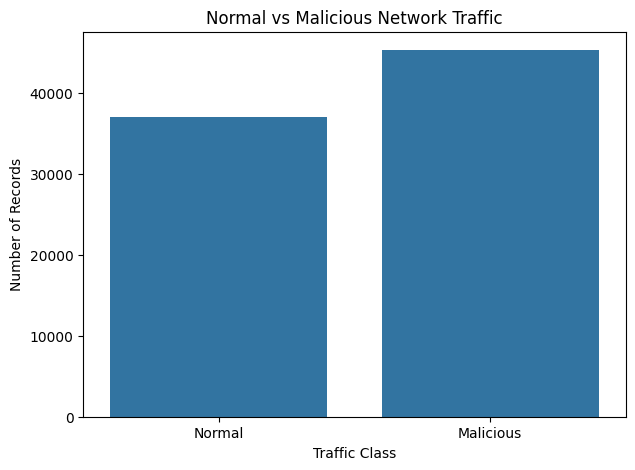

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="label"
)

plt.title("Normal vs Malicious Network Traffic")

plt.xlabel("Traffic Class")

plt.ylabel("Number of Records")

plt.xticks([0, 1], ["Normal", "Malicious"])

plt.show()

Cell 15: Visualize attack categories

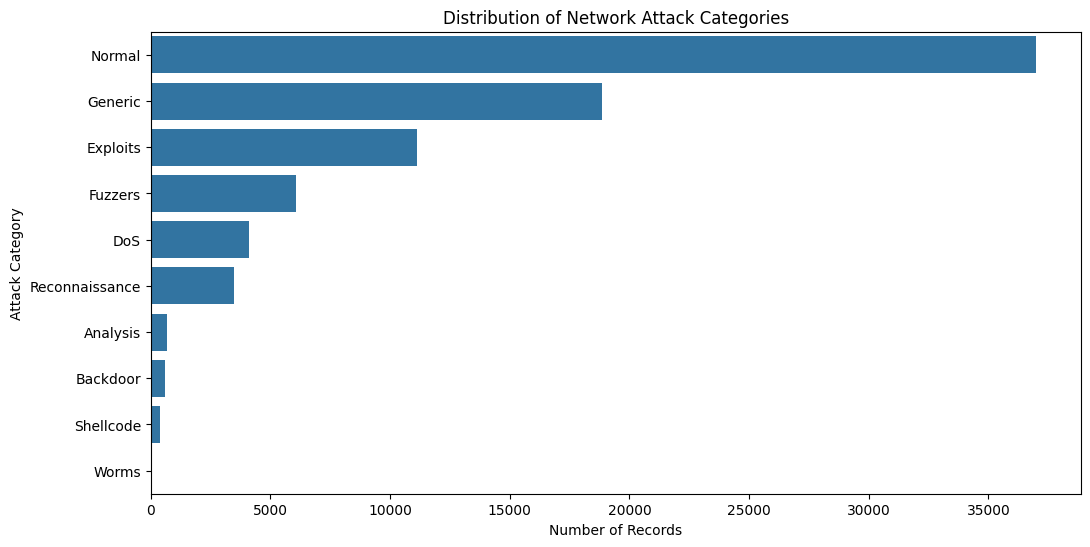

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=train_df,
    y="attack_cat",
    order=train_df["attack_cat"].value_counts().index
)

plt.title("Distribution of Network Attack Categories")

plt.xlabel("Number of Records")

plt.ylabel("Attack Category")

plt.show()

Cell 16: Calculate class distribution percentage

In [ ]:
class_distribution = train_df["label"].value_counts()

class_percentage = (
    train_df["label"].value_counts(normalize=True) * 100
)

distribution_df = pd.DataFrame({
    "Count": class_distribution,
    "Percentage": class_percentage
})

distribution_df.index = [
    "Malicious Traffic" if i == 1 else "Normal Traffic"
    for i in distribution_df.index
]

display(distribution_df)

,Count,Percentage
Malicious Traffic,45332,55.060001
Normal Traffic,37000,44.939999


Cell 17: Visualize numerical feature distributions

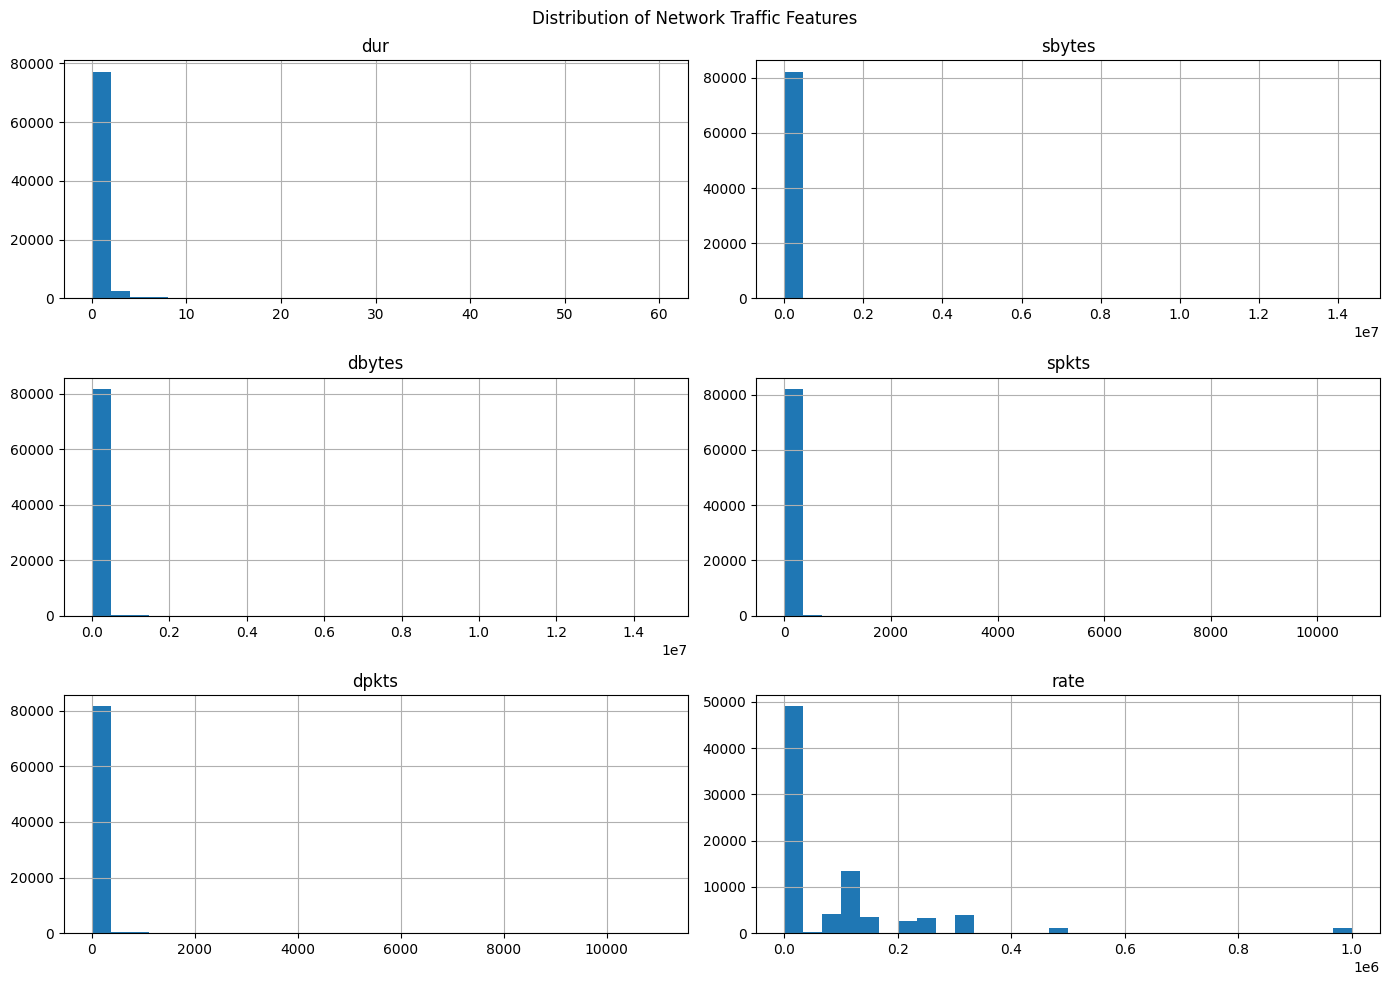

In [ ]:
selected_features = [
    "dur",
    "sbytes",
    "dbytes",
    "spkts",
    "dpkts",
    "rate"
]

train_df[selected_features].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Distribution of Network Traffic Features")

plt.tight_layout()

plt.show()

Cell 18: Correlation heatmap

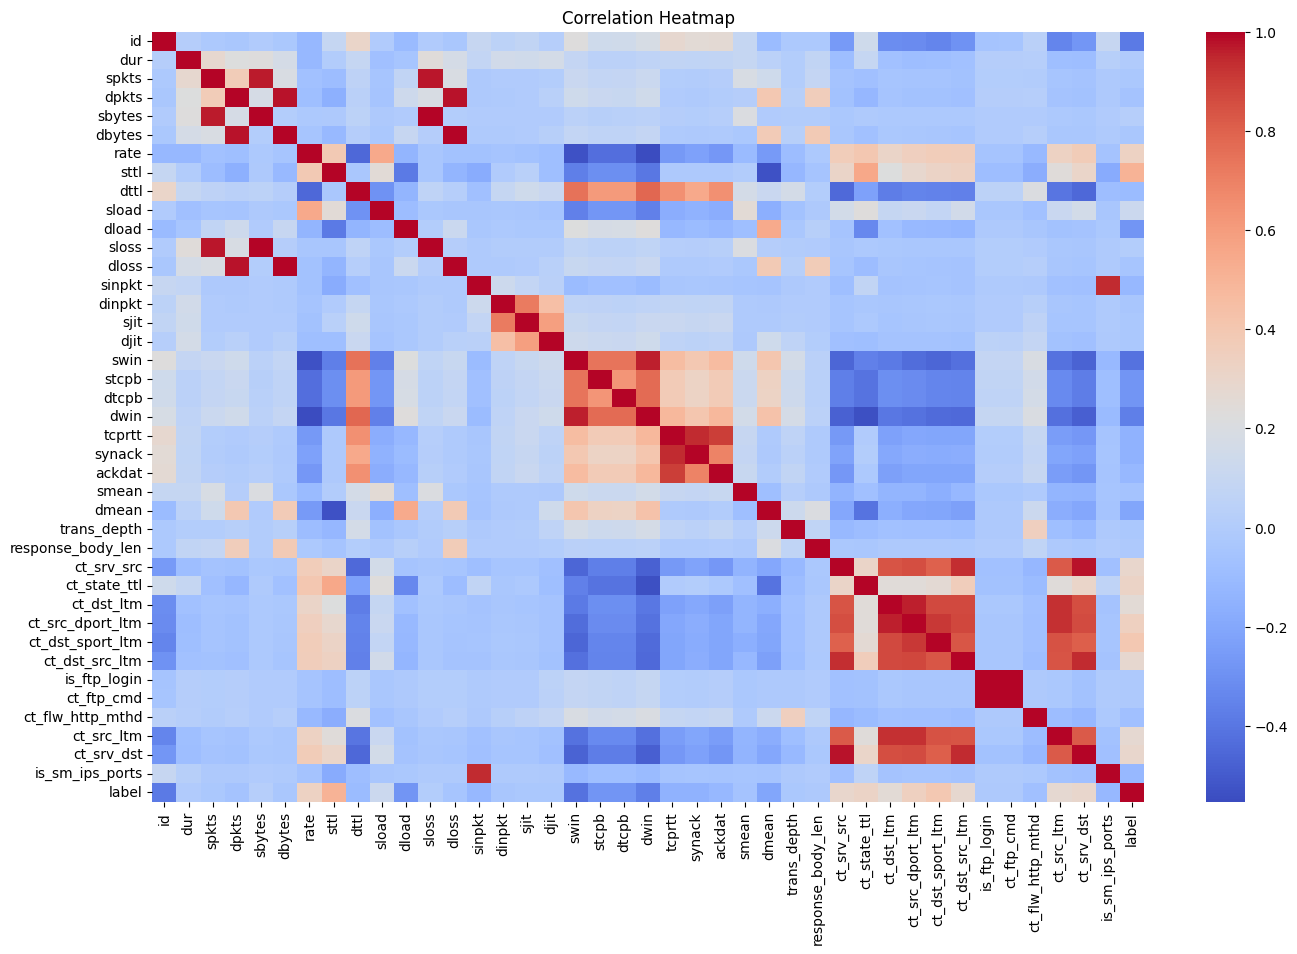

In [ ]:
plt.figure(figsize=(16, 10))

correlation = train_df.select_dtypes(
    include=["number"]
).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Heatmap")

plt.show()

Cell 19: Compare numerical features by traffic class

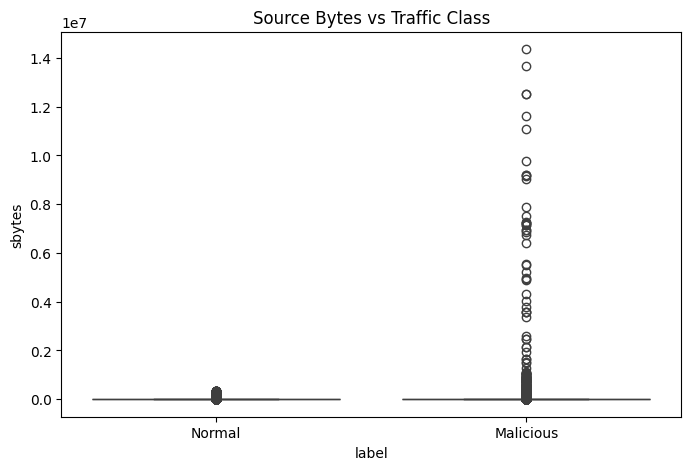

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="label",
    y="sbytes"
)

plt.title("Source Bytes vs Traffic Class")

plt.xticks([0, 1], ["Normal", "Malicious"])

plt.show()

**EDA conclusion:** At this stage, we have examined class distribution, missing values, duplicates, numerical features, categorical features and relationships between network traffic attributes.

**Step 3 – Data preprocessing**

This is one of the most important steps.

We must convert the network traffic information into a format that machine learning algorithms can understand.

Our preprocessing includes:
1. Remove identifier columns.
2. Remove target-derived columns.
3. Handle missing values.
4. Encode categorical features.
5. Scale numerical features.
6. Create a reusable preprocessing pipeline.

**Cell 20: Clean column names**

In [ ]:
train_df.columns = train_df.columns.str.strip()

test_df.columns = test_df.columns.str.strip()

print("Column names cleaned successfully!")

Column names cleaned successfully!


**Cell 21: Separate input features and target**

In [ ]:
# Drop rows where the target 'label' is missing to prevent IntCastingNaNError
train_df = train_df.dropna(subset=["label"])
test_df = test_df.dropna(subset=["label"])

X = train_df.drop(
    columns=["label", "attack_cat", "id"],
    errors="ignore"
)

y = train_df["label"].astype(int)

X_test = test_df.drop(
    columns=["label", "attack_cat", "id"],
    errors="ignore"
)

y_test = test_df["label"].astype(int)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Testing Features Shape:", X_test.shape)

Input Features Shape: (82332, 42)
Target Shape: (82332,)
Testing Features Shape: (175341, 42)


**Cell 22: Replace infinite values**

In [ ]:
X = X.replace([np.inf, -np.inf], np.nan)

X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("Infinite values handled successfully!")

Infinite values handled successfully!


**Cell 23: Identify feature types**

In [ ]:
numeric_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Columns:", len(numeric_columns))

print("Categorical Columns:", len(categorical_columns))

print("\nCategorical Features:")

print(categorical_columns)

Numerical Columns: 39
Categorical Columns: 3

Categorical Features:
['proto', 'service', 'state']


**Cell 24: Create numerical preprocessing pipeline**

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

Explanation:
- SimpleImputer replaces missing numerical values with the median.
- StandardScaler standardizes numerical features.

**Cell 25: Create categorical preprocessing pipeline**

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

Explanation:
- SimpleImputer replaces missing categorical values with the most frequent value.
- OneHotEncoder converts categorical features into numerical columns.

**Cell 26: Combine preprocessing pipelines**

In [ ]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_columns
        ),
        (
            "cat",
            categorical_transformer,
            categorical_columns
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


**Step 4 – Split the dataset**
We will use a slightly more rigorous approach than a simple random 80:20 split.
- First, divide the official training dataset into 80% training and 20% validation.
- Keep the official testing dataset completely untouched.
- Use the validation dataset for initial model comparison.
- Use cross-validation and hyperparameter tuning only on the training portion.
- Finally, evaluate the selected model on the official test dataset.
This gives us an independent final test and avoids using test data during model selection

**Cell 27: Train-validation split (80:20)**

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Validation Data:", X_val.shape)

print("Official Testing Data:", X_test.shape)

Training Data: (65865, 42)
Validation Data: (16467, 42)
Official Testing Data: (175341, 42)


**Cell 28: Check class distribution after splitting**

In [ ]:
print("Training Class Distribution:")

print(y_train.value_counts(normalize=True))

print("\nValidation Class Distribution:")

print(y_val.value_counts(normalize=True))

Training Class Distribution:
label
1    0.550596
0    0.449404
Name: proportion, dtype: float64

Validation Class Distribution:
label
1    0.550616
0    0.449384
Name: proportion, dtype: float64


**Step 5 – Train three classification models**
We will train:
1. Logistic Regression
2. Decision Tree
3. Random Forest
Each model will have its own preprocessing pipeline.


**Cell 29: Create Logistic Regression model**

In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression Model Created!")

Logistic Regression Model Created!


**Cell 30: Create Decision Tree model**

In [ ]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

print("Decision Tree Model Created!")

Decision Tree Model Created!


**Cell 31: Create Random Forest model**

In [ ]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

print("Random Forest Model Created!")

Random Forest Model Created!


**Cell 32: Store all three models**

In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

print("Total Models:", len(models))

for name in models:
    print(name)

Total Models: 3
Logistic Regression
Decision Tree
Random Forest


**Cell 33: Train all three models**


This cell may take some time because the dataset contains many records.

In [ ]:
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "trained successfully!")


Training: Logistic Regression
Logistic Regression trained successfully!

Training: Decision Tree
Decision Tree trained successfully!

Training: Random Forest
Random Forest trained successfully!


**Cell 34: Generate validation predictions**

In [ ]:
validation_predictions = {}

for name, model in trained_models.items():

    predictions = model.predict(X_val)

    validation_predictions[name] = predictions

    print(name, "prediction completed!")

Logistic Regression prediction completed!
Decision Tree prediction completed!
Random Forest prediction completed!


At this point, all three models are trained.

**Step 6 – Evaluate and compare the models**

Now we will check which model performs better.

We will calculate:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix
- Classification report
Remember that recall for malicious traffic is especially important. A false negative means that a malicious network record was incorrectly classified as normal.

**Cell 35: Calculate evaluation metrics**

In [ ]:
results = []

for name, predictions in validation_predictions.items():

    accuracy = accuracy_score(y_val, predictions)

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values(
        by="F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.976316,0.984370,0.972427,0.978362
1,Decision Tree,0.963321,0.967001,0.966362,0.966681
0,Logistic Regression,0.919475,0.929054,0.924341,0.926692


**Cell 36: Plot model performance comparison**

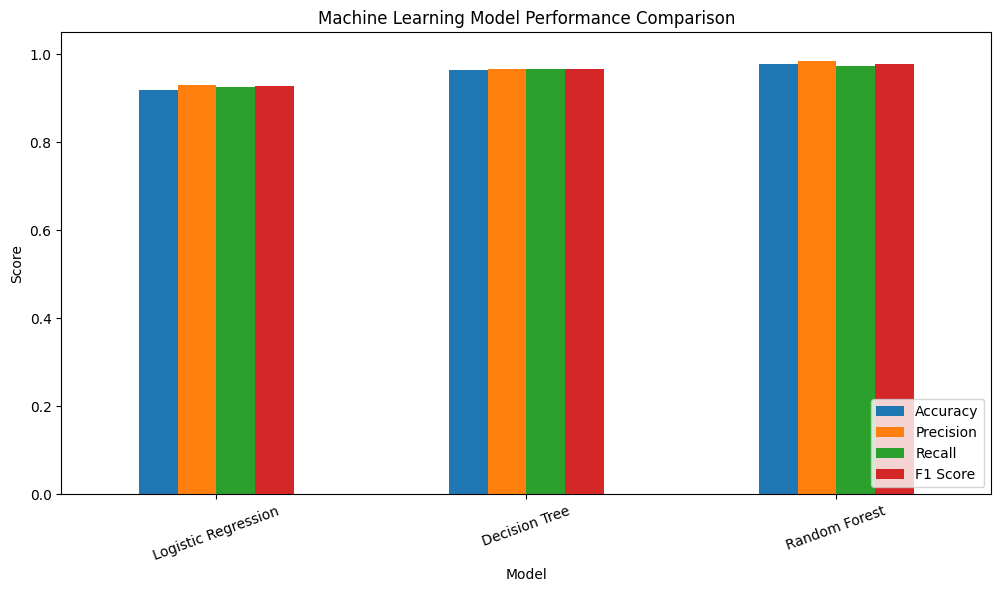

In [ ]:
comparison_plot = comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")

plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=20)

plt.legend(loc="lower right")

plt.show()

**Cell 37: Generate classification reports**

In [ ]:
for name, predictions in validation_predictions.items():

    print("\n====================================")

    print("MODEL:", name)

    print("====================================")

    print(
        classification_report(
            y_val,
            predictions,
            target_names=[
                "Normal Traffic",
                "Malicious Traffic"
            ],
            zero_division=0
        )
    )


MODEL: Logistic Regression
                   precision    recall  f1-score   support

   Normal Traffic       0.91      0.91      0.91      7400
Malicious Traffic       0.93      0.92      0.93      9067

         accuracy                           0.92     16467
        macro avg       0.92      0.92      0.92     16467
     weighted avg       0.92      0.92      0.92     16467


MODEL: Decision Tree
                   precision    recall  f1-score   support

   Normal Traffic       0.96      0.96      0.96      7400
Malicious Traffic       0.97      0.97      0.97      9067

         accuracy                           0.96     16467
        macro avg       0.96      0.96      0.96     16467
     weighted avg       0.96      0.96      0.96     16467


MODEL: Random Forest
                   precision    recall  f1-score   support

   Normal Traffic       0.97      0.98      0.97      7400
Malicious Traffic       0.98      0.97      0.98      9067

         accuracy                  

**Cell 38: Confusion matrices for all three models**

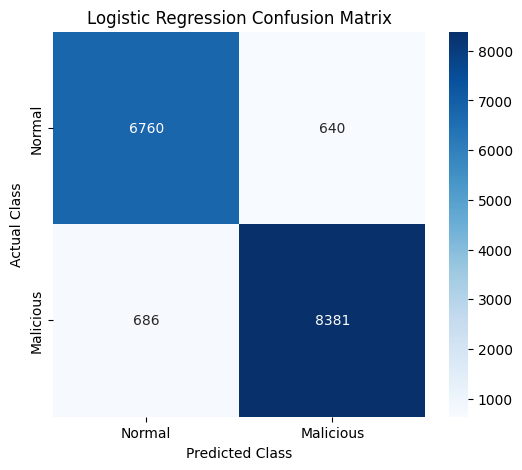

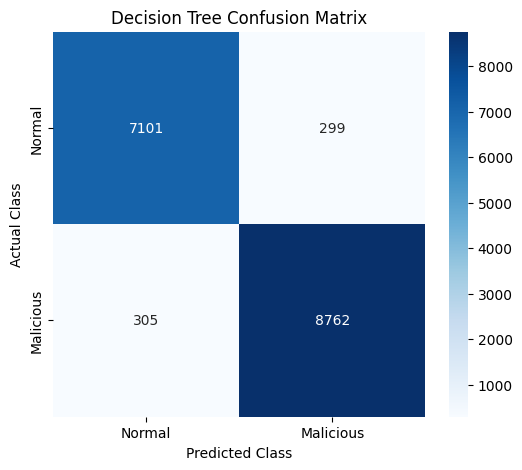

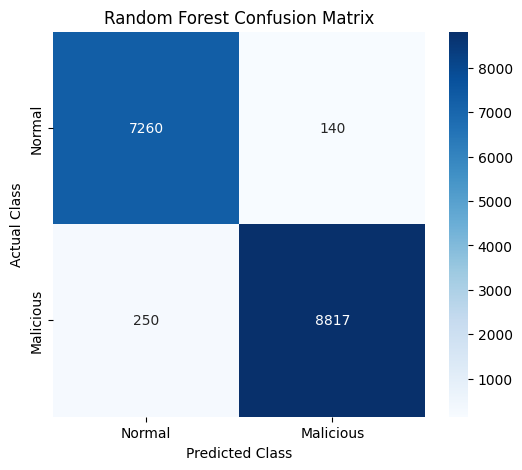

In [ ]:
for name, predictions in validation_predictions.items():

    cm = confusion_matrix(y_val, predictions)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Malicious"],
        yticklabels=["Normal", "Malicious"]
    )

    plt.title(name + " Confusion Matrix")

    plt.xlabel("Predicted Class")

    plt.ylabel("Actual Class")

    plt.show()

**Step 7 – Perform 5-fold cross-validation**

Cross-validation helps us understand whether our models perform consistently across different training and validation subsets.

We will use StratifiedKFold with five folds.

**Cell 39: Create 5-fold cross-validation**

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Cross Validation Created!")

5-Fold Cross Validation Created!


**Cell 40: Perform cross-validation for all three models**

We will use F1-score as the primary cross-validation metric.

In [ ]:
cv_results = {}

for name, model in models.items():

    print("\nCross Validation:", name)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results[name] = scores

    print("Fold Scores:", scores)

    print("Average F1 Score:", scores.mean())

    print("Standard Deviation:", scores.std())


Cross Validation: Logistic Regression
Fold Scores: [0.92202919 0.92334278 0.9234102  0.93160916 0.92196133]
Average F1 Score: 0.9244705302676067
Standard Deviation: 0.003622495024765898

Cross Validation: Decision Tree
Fold Scores: [0.96896385 0.9679735  0.96930489 0.96907926 0.96625809]
Average F1 Score: 0.9683159172386058
Standard Deviation: 0.001125386627109094

Cross Validation: Random Forest
Fold Scores: [0.97699951 0.97689586 0.97855858 0.97812846 0.97802046]
Average F1 Score: 0.977720574920921
Standard Deviation: 0.0006570612118285852


**Cell 41: Create cross-validation comparison table**

In [ ]:
cv_comparison = []

for name, scores in cv_results.items():

    cv_comparison.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Average F1": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_comparison)

display(cv_df)

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average F1,Standard Deviation
0,Logistic Regression,0.922029,0.923343,0.923410,0.931609,0.921961,0.924471,0.003622
1,Decision Tree,0.968964,0.967973,0.969305,0.969079,0.966258,0.968316,0.001125
2,Random Forest,0.977000,0.976896,0.978559,0.978128,0.978020,0.977721,0.000657


**Cell 42: Visualize cross-validation scores**

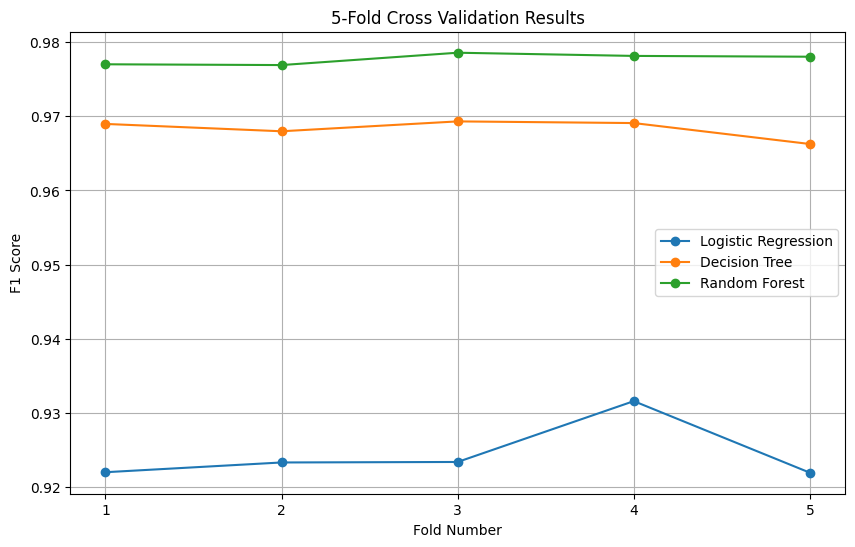

In [ ]:
plt.figure(figsize=(10, 6))

for name, scores in cv_results.items():

    plt.plot(
        range(1, 6),
        scores,
        marker="o",
        label=name
    )

plt.title("5-Fold Cross Validation Results")

plt.xlabel("Fold Number")

plt.ylabel("F1 Score")

plt.xticks(range(1, 6))

plt.legend()

plt.grid(True)

plt.show()

**Step 8 – Hyperparameter tuning using GridSearchCV**

Hyperparameter tuning helps us find better model settings.

We will tune all three models separately.


**Cell 43: Define Logistic Regression parameter grid**

In [ ]:
logistic_params = {
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

Explanation:
- C controls regularization strength.
- class_weight allows us to test whether balancing the classes improves detection.

**Cell 44: Define Decision Tree parameter grid**

In [ ]:
decision_tree_params = {
    "classifier__max_depth": [10, 20, None],

    "classifier__min_samples_split": [2, 5],

    "classifier__min_samples_leaf": [1, 2]
}

**Cell 45: Define Random Forest parameter grid**

In [ ]:
random_forest_params = {
    "classifier__n_estimators": [100, 200],

    "classifier__max_depth": [20, None],

    "classifier__min_samples_split": [2, 5]
}

**Cell 46: Store parameter grids**

In [ ]:
parameter_grids = {
    "Logistic Regression": logistic_params,

    "Decision Tree": decision_tree_params,

    "Random Forest": random_forest_params
}

print("All parameter grids created successfully!")

All parameter grids created successfully!


**Cell 47: Apply GridSearchCV to all models**

This is a computationally intensive cell. GridSearchCV will test the combinations of parameters using five-fold cross-validation.

In [ ]:
best_estimators = {}

grid_results = {}

for name, model in models.items():

    print("\n================================")

    print("TUNING:", name)

    print("================================")

    grid_search = GridSearchCV(
        estimator=model,

        param_grid=parameter_grids[name],

        cv=cv,

        scoring="f1",

        n_jobs=-1,

        verbose=1,

        refit=True
    )

    grid_search.fit(X_train, y_train)

    best_estimators[name] = grid_search.best_estimator_

    grid_results[name] = grid_search

    print("\nBest Parameters:")

    print(grid_search.best_params_)

    print("\nBest Cross Validation F1:")

    print(grid_search.best_score_)


TUNING: Logistic Regression
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best Parameters:
{'classifier__C': 10, 'classifier__class_weight': None}

Best Cross Validation F1:
0.9308005275620506

TUNING: Decision Tree
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best Parameters:
{'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best Cross Validation F1:
0.9704151918919708

TUNING: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross Validation F1:
0.9780254233664365


**Cell 48: Display best hyperparameters**

In [ ]:
tuning_results = []

for name, grid in grid_results.items():

    tuning_results.append({

        "Model": name,

        "Best Parameters": grid.best_params_,

        "Best CV F1 Score": grid.best_score_

    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)

,Model,Best Parameters,Best CV F1 Score
0,Logistic Regression,"{'classifier__C': 10, 'classifier__class_weigh...",0.930801
1,Decision Tree,"{'classifier__max_depth': 20, 'classifier__min...",0.970415
2,Random Forest,"{'classifier__max_depth': None, 'classifier__m...",0.978025


**Cell 49: Compare tuned model scores**

In [ ]:
tuned_comparison = pd.DataFrame({

    "Model": list(grid_results.keys()),

    "Best CV F1": [
        grid_results[name].best_score_
        for name in grid_results
    ]

})

display(
    tuned_comparison.sort_values(
        by="Best CV F1",
        ascending=False
    )
)

,Model,Best CV F1
2,Random Forest,0.978025
1,Decision Tree,0.970415
0,Logistic Regression,0.930801


**Step 9 – Select the best model**

Now we will select the model that achieved the highest average cross-validation F1-score.

We will then train that model again using the complete official training dataset and evaluate it on the untouched official testing dataset.

**Cell 50: Select the best model**

In [ ]:
best_model_name = max(
    grid_results,
    key=lambda name: grid_results[name].best_score_
)

best_model = best_estimators[best_model_name]

print("Best Performing Model:", best_model_name)

print(
    "Best Cross Validation F1:",
    grid_results[best_model_name].best_score_
)

Best Performing Model: Random Forest
Best Cross Validation F1: 0.9780254233664365


**Cell 51: Retrain the selected model on the complete training dataset**

In [ ]:
print("Retraining:", best_model_name)

best_model.fit(X, y)

print("Final Model Training Completed!")

Retraining: Random Forest
Final Model Training Completed!


This refits both the preprocessing and classification steps on all 175,341 official training records.

**Cell 52: Predict official testing data**

In [ ]:
final_predictions = best_model.predict(X_test)

print("Testing Predictions Completed!")

Testing Predictions Completed!


**Cell 53: Calculate final performance metrics**

In [ ]:
final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    final_predictions,
    zero_division=0
)

print("FINAL MODEL:", best_model_name)

print("--------------------------------")

print("Accuracy:", final_accuracy)

print("Precision:", final_precision)

print("Recall:", final_recall)

print("F1 Score:", final_f1)

FINAL MODEL: Random Forest
--------------------------------
Accuracy: 0.9052360828328799
Precision: 0.9874443632498505
Recall: 0.871854601520014
F1 Score: 0.926056463384243


**Cell 54: Final classification report**

In [ ]:
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=[
            "Normal Traffic",
            "Malicious Traffic"
        ],
        zero_division=0
    )
)

                   precision    recall  f1-score   support

   Normal Traffic       0.78      0.98      0.87     56000
Malicious Traffic       0.99      0.87      0.93    119341

         accuracy                           0.91    175341
        macro avg       0.88      0.92      0.90    175341
     weighted avg       0.92      0.91      0.91    175341



**Cell 55: Final confusion matrix**

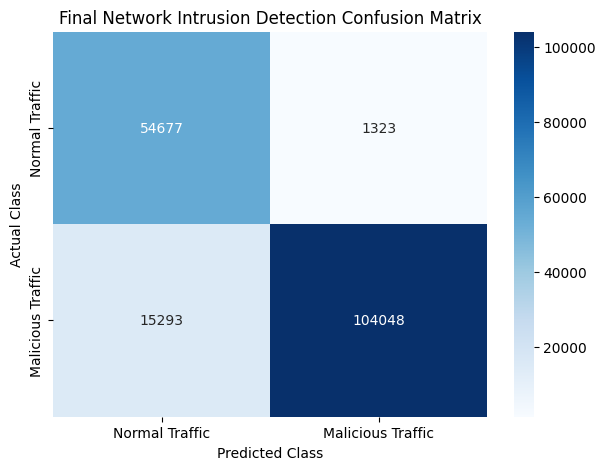

In [ ]:
cm = confusion_matrix(
    y_test,
    final_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal Traffic",
        "Malicious Traffic"
    ],
    yticklabels=[
        "Normal Traffic",
        "Malicious Traffic"
    ]
)

plt.title("Final Network Intrusion Detection Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.show()

**Cell 56: Save final evaluation results**

In [ ]:
final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]

})

display(final_results)

final_results.to_csv(
    "final_model_evaluation.csv",
    index=False
)

print("Evaluation results saved!")

,Metric,Score
0,Accuracy,0.905236
1,Precision,0.987444
2,Recall,0.871855
3,F1 Score,0.926056


Evaluation results saved!


**Step 10 – Classify new, unseen network data**

Now we will create the actual prediction functionality.

The user will provide network traffic features through a CSV file. Our saved model will classify the records.

The prediction pipeline will automatically perform:
1. Missing-value handling.
2. Categorical encoding.
3. Numerical scaling.
4. Classification.
We do not need to manually preprocess new records again.

**Cell 57: Create a sample input template**

This generates a CSV file containing all required input columns.

The values are initial placeholders based on the training data. Replace them with actual network traffic feature values before treating the record as a new observation.

In [ ]:
sample_record = {}

for column in X.columns:

    if column in numeric_columns:

        sample_record[column] = X[column].median()

    else:

        sample_record[column] = X[column].mode()[0]

sample_input = pd.DataFrame([sample_record])

sample_input.to_csv(
    "new_network_records_template.csv",
    index=False
)

print("New Network Record Template Created!")

display(sample_input)

New Network Record Template Created!


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
0,0.014138,tcp,-,FIN,6.0,2.0,534.0,178.0,2650.176667,254.0,...,2.0,1.0,1.0,3.0,0.0,0.0,0.0,3.0,5.0,0.0


**Cell 58: Download the input template**

In [ ]:
from google.colab import files

files.download("new_network_records_template.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Cell 59: Create prediction function**

In [ ]:
def predict_network_traffic(input_data):

    # Check required columns
    missing_columns = set(X.columns) - set(input_data.columns)

    if missing_columns:

        raise ValueError(
            "Missing required columns: "
            + str(missing_columns)
        )

    # Select columns in correct order
    input_data = input_data[X.columns]

    # Handle infinite values
    input_data = input_data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Predict
    predictions = best_model.predict(input_data)

    # Convert numerical output into labels
    results = []

    for prediction in predictions:

        if prediction == 0:

            results.append("Normal Traffic")

        else:

            results.append("Malicious Traffic")

    return results

**Cell 60: Upload new network traffic records**

In [ ]:
from google.colab import files

uploaded = files.upload()

new_data = pd.read_csv(
    next(iter(uploaded))
)

print("New Network Data Loaded!")

display(new_data.head())

Saving new_network_records_template.csv to new_network_records_template (1).csv
New Network Data Loaded!


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
0,0.014138,tcp,-,FIN,6.0,2.0,534.0,178.0,2650.176667,254.0,...,2.0,1.0,1.0,3.0,0.0,0.0,0.0,3.0,5.0,0.0


**Cell 61: Predict new network traffic**

In [ ]:
predicted_results = predict_network_traffic(new_data)

new_data["Predicted_Result"] = predicted_results

display(new_data[["Predicted_Result"]])

,Predicted_Result
0,Normal Traffic


**Cell 62: Display final prediction summary**

In [ ]:
for i, result in enumerate(predicted_results):

    print("\nNetwork Record:", i + 1)

    print("Predicted Class:", result)

    if result == "Malicious Traffic":

        print("Warning: Suspicious network traffic detected!")

    else:

        print("Network traffic classified as normal.")


Network Record: 1
Predicted Class: Normal Traffic
Network traffic classified as normal.


This is an illustrative output. The actual prediction depends on the trained model and the input record.

**Cell 63: Save prediction results**

In [ ]:
new_data.to_csv(
    "network_prediction_results.csv",
    index=False
)

print("Prediction results saved successfully!")

Prediction results saved successfully!


**Step 11 – Save the model and preprocessing pipeline**

We will save the complete pipeline rather than saving only the classifier.

This is important because the saved model must remember the categorical encoding, numerical scaling and missing-value handling used during training.

**Cell 64: Create project directories**

In [ ]:
os.makedirs("models", exist_ok=True)

os.makedirs("outputs", exist_ok=True)

print("Project directories created!")

Project directories created!


**Cell 65: Save the final model**

In [ ]:
joblib.dump(
    best_model,
    "models/network_intrusion_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


**Cell 66: Save the model information**

In [ ]:
model_information = {

    "model_name": best_model_name,

    "target": "label",

    "class_mapping": {
        0: "Normal Traffic",
        1: "Malicious Traffic"
    },

    "features": list(X.columns),

    "accuracy": float(final_accuracy),

    "precision": float(final_precision),

    "recall": float(final_recall),

    "f1_score": float(final_f1),

    "best_parameters": grid_results[
        best_model_name
    ].best_params_

}

joblib.dump(
    model_information,
    "models/model_information.pkl"
)

print("Model information saved!")

Model information saved!


**Cell 67: Load the saved model**

In [ ]:
loaded_model = joblib.load(
    "models/network_intrusion_model.pkl"
)

print("Saved Model Loaded Successfully!")

Saved Model Loaded Successfully!


**Cell 68: Test the loaded model**

In [ ]:
test_prediction = loaded_model.predict(
    X_test.iloc[:5]
)

print("Predictions from saved model:")

for prediction in test_prediction:

    if prediction == 0:

        print("Normal Traffic")

    else:

        print("Malicious Traffic")

Predictions from saved model:
Malicious Traffic
Malicious Traffic
Malicious Traffic
Malicious Traffic
Normal Traffic


**5. Build the web application using Streamlit**

We have completed the machine learning portion. Now let's create a simple web application where someone can upload network traffic records and receive predictions.

**Cell 69: Create** app.py

Run this cell to generate your Streamlit application file.

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Network Intrusion Detection",
    page_icon="🛡️",
    layout="wide"
)

# Load trained model
model = joblib.load(
    "models/network_intrusion_model.pkl"
)

model_info = joblib.load(
    "models/model_information.pkl"
)

st.title("🛡️ Network Intrusion Detection System")

st.write(
    "Machine Learning Based Network Traffic Classification"
)

st.divider()

st.subheader("Project Information")

col1, col2, col3 = st.columns(3)

col1.metric(
    "Selected Model",
    model_info["model_name"]
)

col2.metric(
    "Accuracy",
    f"{model_info['accuracy'] * 100:.2f}%"
)

col3.metric(
    "F1 Score",
    f"{model_info['f1_score'] * 100:.2f}%"
)

st.divider()

st.subheader("Upload Network Traffic Data")

uploaded_file = st.file_uploader(
    "Upload CSV file containing network features",
    type=["csv"]
)

if uploaded_file is not None:

    data = pd.read_csv(uploaded_file)

    st.write("Uploaded Network Records")

    st.dataframe(data.head())

    required_features = model_info["features"]

    missing_columns = [
        col for col in required_features
        if col not in data.columns
    ]

    if missing_columns:

        st.error(
            "Missing required features: "
            + ", ".join(missing_columns)
        )

    else:

        if st.button("Detect Network Intrusion"):

            input_data = data[required_features].copy()

            input_data = input_data.replace(
                [float("inf"), float("-inf")],
                float("nan")
            )

            predictions = model.predict(input_data)

            result_data = data.copy()

            result_data["Prediction"] = [
                "Normal Traffic" if p == 0
                else "Malicious Traffic"
                for p in predictions
            ]

            st.subheader("Detection Results")

            st.dataframe(result_data)

            normal_count = sum(predictions == 0)

            malicious_count = sum(predictions == 1)

            col1, col2 = st.columns(2)

            col1.metric(
                "Normal Records",
                int(normal_count)
            )

            col2.metric(
                "Malicious Records",
                int(malicious_count)
            )

            if malicious_count > 0:

                st.error(
                    "Warning: Malicious network traffic detected!"
                )

            else:

                st.success(
                    "No malicious records detected in this upload."
                )

            st.download_button(
                label="Download Prediction Results",
                data=result_data.to_csv(index=False),
                file_name="network_prediction_results.csv",
                mime="text/csv"
            )

st.divider()

st.caption(
    "MCA Final-Year PBL Project | Network Intrusion Detection System"
)

Writing app.py


**Cell 70: Create** predict.py **for command-line prediction**

In [ ]:
%%writefile predict.py

import pandas as pd
import joblib
import sys

model = joblib.load(
    "models/network_intrusion_model.pkl"
)

model_info = joblib.load(
    "models/model_information.pkl"
)

if len(sys.argv) < 2:

    print("Usage: python predict.py input.csv")

    sys.exit(1)

file_path = sys.argv[1]

data = pd.read_csv(file_path)

required_features = model_info["features"]

missing = set(required_features) - set(data.columns)

if missing:

    print("Missing features:", missing)

    sys.exit(1)

input_data = data[required_features].copy()

input_data = input_data.replace(
    [float("inf"), float("-inf")],
    float("nan")
)

predictions = model.predict(input_data)

for i, prediction in enumerate(predictions):

    print("\nNetwork Record:", i + 1)

    if prediction == 0:

        print("Result: Normal Traffic")

    else:

        print("Result: Malicious Traffic")

data["Prediction"] = [
    "Normal Traffic" if p == 0
    else "Malicious Traffic"
    for p in predictions
]

data.to_csv(
    "prediction_results.csv",
    index=False
)

print("\nPrediction completed!")

Writing predict.py


**Cell 71: Create** requirements.txt

In [ ]:
%%writefile requirements.txt

pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
streamlit

Writing requirements.txt


**Cell 72: Create the final project ZIP**

In [ ]:
import shutil

shutil.make_archive(
    "Network_Intrusion_Detection",
    "zip",
    ".",
    base_dir="."
)

print("Project ZIP created successfully!")

**Cell 73: Download the project ZIP**

In [ ]:
from google.colab import files

files.download(
    "Network_Intrusion_Detection.zip"
)